
**Topic:** *Evaluating AI-Based Streamflow Forecasts for Improving Electricity Supply Reliability During Droughts in Ecuador*.


## 1. Libraries and configuration

In [26]:

# 1. LIBRARIES AND CONFIGURATION


import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor


FILE_PATH = Path(
    r"C:\Users\DETPC\Downloads\proyecto\Supplementary File S1.xlsx"
)

SHEET_NAME = 0
DATE_COL = None
YEAR_COL = None
MONTH_COL = None
FLOW_COL = None

# Predict one month ahead
FORECAST_HORIZON = 1

OUTPUT_DIR = FILE_PATH.parent / "results_paute"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("File path:", FILE_PATH)
print("File exists:", FILE_PATH.exists())

if not FILE_PATH.is_file():
    raise FileNotFoundError(
        f"Excel file not found: {FILE_PATH}"
    )
excel = pd.ExcelFile(FILE_PATH) 
df = pd.read_excel(FILE_PATH, header=3)
print("Available sheets:", excel.sheet_names)   
    
df = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAME)

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head().to_string(index=False))


File path: C:\Users\DETPC\Downloads\proyecto\Supplementary File S1.xlsx
File exists: True
Available sheets: ['Dataset_monthly', 'Quality_control', 'Monthly_climatology', 'Annual_summary', 'Model_selection', 'Parameter_diagnostics', 'Residual_diagnostics', 'Backtest_rolling', 'PI_coverage', 'Prob_verification', 'Threshold_sensitivity', 'Forecast_2026', 'Forecast_2026_2030', 'Forecast_highest_risk', 'Dry_wet_years']

Dataset shape:
(507, 6)

Column names:
['Processed monthly streamflow dataset', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']

First five rows:
                                                                                                 Processed monthly streamflow dataset Unnamed: 1 Unnamed: 2 Unnamed: 3     Unnamed: 4         Unnamed: 5
Monthly mean streamflow compiled for the Paute River basin. Dates are stored as sortable Excel dates; streamflow is reported in m3/s.        NaN        NaN        NaN            NaN                NaN
           

In [25]:
print(excel.sheet_names)
print(df.columns.tolist())
print(df.head())

['Dataset_monthly', 'Quality_control', 'Monthly_climatology', 'Annual_summary', 'Model_selection', 'Parameter_diagnostics', 'Residual_diagnostics', 'Backtest_rolling', 'PI_coverage', 'Prob_verification', 'Threshold_sensitivity', 'Forecast_2026', 'Forecast_2026_2030', 'Forecast_highest_risk', 'Dry_wet_years']
['Processed monthly streamflow dataset', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']
                Processed monthly streamflow dataset Unnamed: 1 Unnamed: 2  \
0  Monthly mean streamflow compiled for the Paute...        NaN        NaN   
1                                                NaN        NaN        NaN   
2                                               Date       Year      Month   
3                                1984-01-31 00:00:00       1984          1   
4                                1984-02-29 00:00:00       1984          2   

   Unnamed: 3      Unnamed: 4          Unnamed: 5  
0         NaN             NaN                 NaN  
1     

## 2. Locate and inspect the Excel file

In [30]:


import pandas as pd
from pathlib import Path

# 1. Define the Excel file location
FILE_PATH = Path(
    r"C:\Users\DETPC\Downloads\proyecto\Supplementary File S1.xlsx"
)

# 2. Verify that the file exists
if not FILE_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {FILE_PATH}"
    )

# 3. Open the Excel workbook
book = pd.ExcelFile(FILE_PATH)

print("Available sheets:")
print(book.sheet_names)

# 4. Read the monthly streamflow dataset
raw_sheet = pd.read_excel(
    FILE_PATH,
    sheet_name="Dataset_monthly",
    header=3
)

# 5. Display column names
print("\nColumn names:")
print(raw_sheet.columns.tolist())

# 6. Display dataset dimensions
print("\nDataset shape:")
print(raw_sheet.shape)

# 7. Display the first observations
print("\nFirst five rows:")
print(raw_sheet.head().to_string(index=False))

# 8. Display data types
print("\nData types:")
print(raw_sheet.dtypes)


Available sheets:
['Dataset_monthly', 'Quality_control', 'Monthly_climatology', 'Annual_summary', 'Model_selection', 'Parameter_diagnostics', 'Residual_diagnostics', 'Backtest_rolling', 'PI_coverage', 'Prob_verification', 'Threshold_sensitivity', 'Forecast_2026', 'Forecast_2026_2030', 'Forecast_highest_risk', 'Dry_wet_years']

Column names:
['Date', 'Year', 'Month', 'Month_name', 'Streamflow_m3s', 'Source_worksheet']

Dataset shape:
(504, 6)

First five rows:
      Date  Year  Month Month_name  Streamflow_m3s   Source_worksheet
1984-01-31  1984      1    January       44.820742 Hydrology_CSR_1984
1984-02-29  1984      2   February      159.010103 Hydrology_CSR_1984
1984-03-31  1984      3      March      145.894129 Hydrology_CSR_1984
1984-04-30  1984      4      April      245.954133 Hydrology_CSR_1984
1984-05-31  1984      5        May      102.469677 Hydrology_CSR_1984

Data types:
Date                datetime64[ns]
Year                         int64
Month                        int6

## 3. Identify and clean observed flow data

In [28]:
import pandas as pd

# Read the actual data sheet
raw_sheet = pd.read_excel(
    FILE_PATH,
    sheet_name="Dataset_monthly",
    header=3
)

# Select the columns needed for forecasting
monthly = raw_sheet[
    ["Date", "Streamflow_m3s"]
].copy()

# Rename columns
monthly = monthly.rename(columns={
    "Date": "date",
    "Streamflow_m3s": "flow"
})

# Convert data types
monthly["date"] = pd.to_datetime(
    monthly["date"],
    errors="coerce"
)

monthly["flow"] = pd.to_numeric(
    monthly["flow"],
    errors="coerce"
)

# Check invalid dates before removing rows
if monthly["date"].isna().any():
    raise ValueError("Invalid dates found.")

# Convert to monthly timestamps
monthly["date"] = (
    monthly["date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Sort records chronologically
monthly = monthly.sort_values("date")

# Check duplicated months
if monthly["date"].duplicated().any():
    raise ValueError("Duplicated months found.")

# Use dates as index and enforce monthly frequency
monthly = monthly.set_index("date").asfreq("MS")

# Check missing values and invalid streamflows
if monthly["flow"].isna().any():
    raise ValueError("Missing or invalid streamflow values.")

if (monthly["flow"] < 0).any():
    raise ValueError("Negative streamflow values found.")

# Display the audit results
print("Total months:", len(monthly))
print("Date range:", monthly.index.min(), monthly.index.max())
print("Missing values:", monthly["flow"].isna().sum())

print("\nStreamflow statistics:")
print(monthly["flow"].describe())

print("\nFirst five rows:")
print(monthly.head())

Total months: 504
Date range: 1984-01-01 00:00:00 2025-12-01 00:00:00
Missing values: 0

Streamflow statistics:
count    504.000000
mean     119.043731
std       61.902560
min       25.837822
25%       73.121647
50%      106.617847
75%      150.263798
max      367.430446
Name: flow, dtype: float64

First five rows:
                  flow
date                  
1984-01-01   44.820742
1984-02-01  159.010103
1984-03-01  145.894129
1984-04-01  245.954133
1984-05-01  102.469677


## 4. Features and chronological division

In [31]:
features_df = monthly.copy()
for lag in [1, 2, 3, 6, 12]:
    features_df[f'lag_{lag}'] = features_df['flow'].shift(lag)
for window in [3, 6]:
    features_df[f'rolling_mean_{window}'] = (
        features_df['flow'].shift(1).rolling(window=window).mean()
    )
features_df['month_sin'] = np.sin(2*np.pi * features_df.index.month / 12)
features_df['month_cos'] = np.cos(2*np.pi * features_df.index.month / 12)

feature_cols = [
    'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12',
    'rolling_mean_3', 'rolling_mean_6', 'month_sin', 'month_cos'
]
data = features_df.dropna(subset=feature_cols + ['flow'])

train = data.loc[:'2016-12-01'].copy()
val = data.loc['2017-01-01':'2022-12-01'].copy()
test = data.loc['2023-01-01':'2024-12-01'].copy()
trainval = data.loc[:'2022-12-01'].copy()

assert len(train) >= 60, 'Not enough training observations.'
assert len(val) == 72, 'Expected 72 validation months (2017-2022).'
assert len(test) == 24, 'Expected 24 testing months (2023-2024).'

print('\nChronological partition:')
print('Train:', len(train), train.index.min().date(), train.index.max().date())
print('Validation:', len(val), val.index.min().date(), val.index.max().date())
print('Test:', len(test), test.index.min().date(), test.index.max().date())




Chronological partition:
Train: 384 1985-01-01 2016-12-01
Validation: 72 2017-01-01 2022-12-01
Test: 24 2023-01-01 2024-12-01


## 5. Baselines and AI models

In [32]:

def models_to_compare():
    return {
        'Random Forest': RandomForestRegressor(
            n_estimators=200, max_depth=8, min_samples_leaf=3,
            random_state=42, n_jobs=-1
        ),
        'XGBoost': XGBRegressor(
            n_estimators=250, max_depth=3, learning_rate=0.04,
            subsample=0.9, colsample_bytree=0.9,
            objective='reg:squarederror', random_state=42, n_jobs=2
        ),
    }


def sarima_walk_forward(history_flow, observed_future):
    """One-month-ahead log-SARIMA forecast; update only after the month is observed."""
    history = np.log1p(history_flow.asfreq('MS'))
    model = SARIMAX(
        history, order=(1, 0, 0), seasonal_order=(1, 1, 0, 12),
        trend='n', enforce_stationarity=False, enforce_invertibility=False
    )
    fitted = model.fit(disp=False, maxiter=120)
    predictions = []
    for date, actual in observed_future.items():
        log_forecast = float(fitted.get_forecast(steps=1).predicted_mean.iloc[0])
        predictions.append(max(0., float(np.expm1(log_forecast))))
        new_observation = pd.Series(
            [np.log1p(actual)], index=pd.DatetimeIndex([date]), name='flow'
        )
        fitted = fitted.append(new_observation, refit=False)
    return np.asarray(predictions)


def metrics(actual, pred):
    return {
        'MAE (m3/s)': mean_absolute_error(actual, pred),
        'RMSE (m3/s)': np.sqrt(mean_squared_error(actual, pred))
    }



## 6. Validation: 2017–2022

In [33]:
validation_predictions = {
    'Seasonal Naive': val['lag_12'].to_numpy(),
    'Persistence': val['lag_1'].to_numpy(),
}
validation_predictions['SARIMA'] = sarima_walk_forward(
    monthly.loc[:'2016-12-01', 'flow'],
    monthly.loc['2017-01-01':'2022-12-01', 'flow']
)

for name, model in models_to_compare().items():
    model.fit(train[feature_cols], train['flow'])
    validation_predictions[name] = np.maximum(0, model.predict(val[feature_cols]))

validation_results = pd.DataFrame([
    {'Model': name, **metrics(val['flow'], p)}
    for name, p in validation_predictions.items()
]).sort_values('MAE (m3/s)').reset_index(drop=True)
print('\nVALIDATION RESULTS (2017-2022):')
print(validation_results.round(3).to_string(index=False))

ai_validation = validation_results[
    validation_results['Model'].isin(['Random Forest', 'XGBoost'])
]
best_ai_name = ai_validation.iloc[0]['Model']
print('\nAI model selected using ONLY validation MAE:', best_ai_name)




VALIDATION RESULTS (2017-2022):
         Model  MAE (m3/s)  RMSE (m3/s)
 Random Forest      33.242       41.380
       XGBoost      35.450       45.075
        SARIMA      41.904       55.677
Seasonal Naive      46.036       59.981
   Persistence      46.786       62.559

AI model selected using ONLY validation MAE: Random Forest


## 7. Test: 2023–2024

In [34]:
predictions = pd.DataFrame(index=test.index)
predictions.index.name = 'date'
predictions['Observed'] = test['flow']
predictions['Seasonal Naive'] = test['lag_12']
predictions['Persistence'] = test['lag_1']
predictions['SARIMA'] = sarima_walk_forward(
    monthly.loc[:'2022-12-01', 'flow'],
    monthly.loc['2023-01-01':'2024-12-01', 'flow']
)

fitted_models = {}
for name, model in models_to_compare().items():
    model.fit(trainval[feature_cols], trainval['flow'])
    predictions[name] = np.maximum(0, model.predict(test[feature_cols]))
    fitted_models[name] = model

test_results = pd.DataFrame([
    {'Model': name, **metrics(predictions['Observed'], predictions[name])}
    for name in ['Seasonal Naive', 'Persistence', 'SARIMA', 'Random Forest', 'XGBoost']
]).sort_values('MAE (m3/s)').reset_index(drop=True)

print('\nTEST RESULTS (2023-2024):')
print(test_results.round(3).to_string(index=False))




TEST RESULTS (2023-2024):
         Model  MAE (m3/s)  RMSE (m3/s)
   Persistence      24.532       31.031
       XGBoost      29.527       38.267
Seasonal Naive      29.746       38.662
 Random Forest      31.061       39.741
        SARIMA      33.088       42.533


## 8. Analysis of months with low flow

In [35]:
low_threshold = float(trainval['flow'].quantile(0.20))
low_mask = predictions['Observed'] <= low_threshold
print(f'\nLow-flow threshold (20th percentile of pre-test history): {low_threshold:.3f} m3/s')
print('Low-flow months in test:', int(low_mask.sum()))

lowflow_results = []
for model in ['Seasonal Naive', 'Persistence', 'SARIMA', 'Random Forest', 'XGBoost']:
    lowflow_results.append({
        'Model': model,
        'Low-flow MAE (m3/s)': (
            mean_absolute_error(predictions.loc[low_mask, 'Observed'],
                                predictions.loc[low_mask, model])
            if low_mask.any() else np.nan
        )
    })
lowflow_results = pd.DataFrame(lowflow_results)
print(lowflow_results.round(3).to_string(index=False))




Low-flow threshold (20th percentile of pre-test history): 65.389 m3/s
Low-flow months in test: 11
         Model  Low-flow MAE (m3/s)
Seasonal Naive               24.321
   Persistence               21.428
        SARIMA               26.794
 Random Forest               28.307
       XGBoost               30.208


## 9. Export actual tables and charts

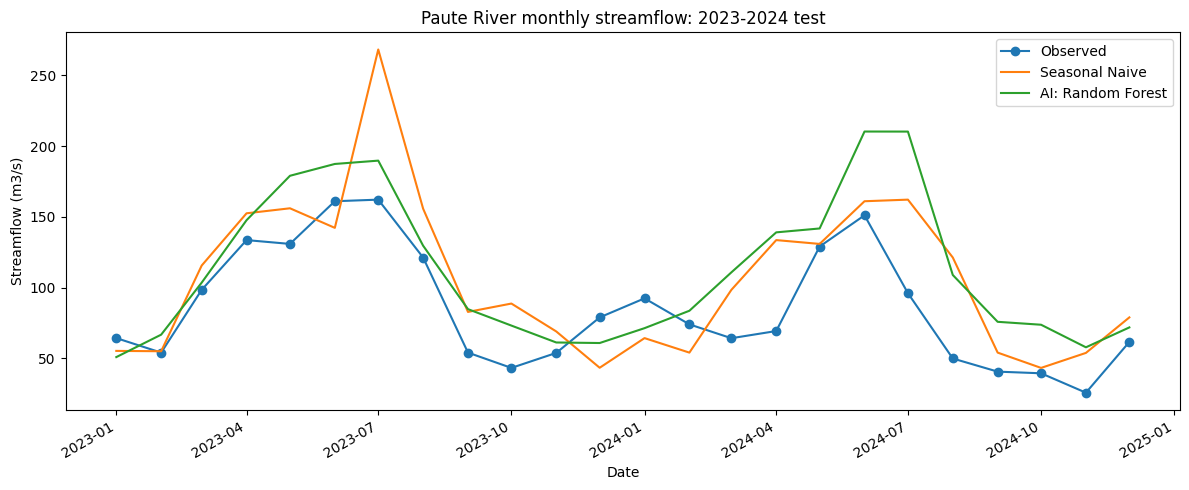

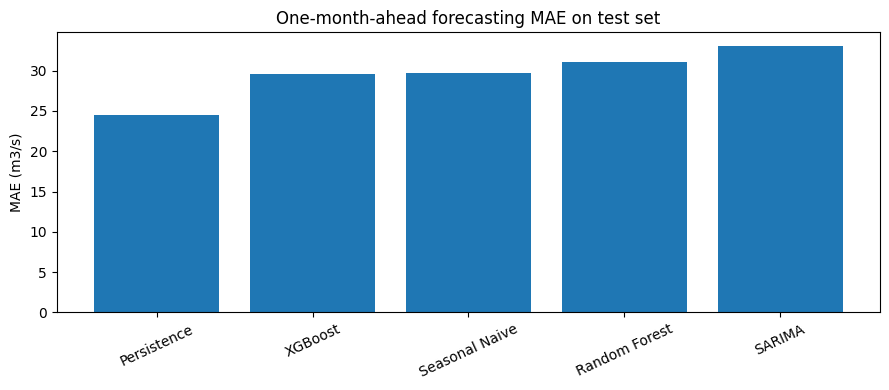

In [37]:
validation_results.to_csv(OUTPUT_DIR / 'paute_validation_metrics.csv', index=False)
test_results.to_csv(OUTPUT_DIR / 'paute_test_metrics.csv', index=False)
lowflow_results.to_csv(OUTPUT_DIR / 'paute_lowflow_metrics.csv', index=False)
predictions.to_csv(OUTPUT_DIR / 'paute_test_predictions.csv', index=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(predictions.index, predictions['Observed'], marker='o', label='Observed')
ax.plot(predictions.index, predictions['Seasonal Naive'], label='Seasonal Naive')
ax.plot(predictions.index, predictions[best_ai_name], label=f'AI: {best_ai_name}')
ax.set(title='Paute River monthly streamflow: 2023-2024 test',
       xlabel='Date', ylabel='Streamflow (m3/s)')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'paute_test_forecasts.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(test_results['Model'], test_results['MAE (m3/s)'])
ax.set(title='One-month-ahead forecasting MAE on test set',
       ylabel='MAE (m3/s)')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'paute_test_mae.png', dpi=160)
plt.show()

with open(OUTPUT_DIR / 'paute_preliminary_results.md', 'w', encoding='utf-8') as f:
    f.write('# 6. Preliminary Results — Paute streamflow forecasting\n\n')
    f.write('Dataset: monthly observed streamflow in Paute, sourced from Zenodo 20213449.\n\n')
    f.write('Target: one-month-ahead streamflow (m3/s).\n\n')
    f.write('Train: through 2016; validation: 2017-2022; test: 2023-2024.\n\n')
    f.write('## Validation results\n\n')
    f.write('```text\n' + validation_results.round(3).to_string(index=False) + '\n```')
    f.write('\n\n## Test results\n\n')
    f.write('```text\n' + test_results.round(3).to_string(index=False) + '\n```')
    f.write(f'\n\nAI model selected on validation: {best_ai_name}.\n')
    f.write('\nThese are forecasting results, not simulated electricity reliability results.\n')

